# Лабораторная работа 1

In [146]:
import matplotlib.pyplot as plt

### Рабочий класс

In [147]:
class DataFrame:
    def __init__(self, filepath: str, x_column = 0, y_column = -1):
        self.data = []
        self.headers = []
    
        with open(filepath) as file:
            self.headers = file.readline().split(',')
            self.headers[-1] = self.headers[-1][:-1:]
    
            line = file.readline()
            while line:
                line_data = list(map(float, line.split(',')))
                self.data.append([line_data[x_column], line_data[y_column]])
    
                line = file.readline()

    def __str__(self):
        res = ' '.join(self.headers)

        if len(self.data) == 0:
            return res

        str_data = [res]

        for d in self.data:
            d_str = ' '.join(map(str, d))
            str_data.append(d_str)

        return '\n'.join(str_data)


    def size(self):
        if len(self.data) == 0:
            return (0, 0)

        return (len(self.data), len(self.data[0]))

    def min(self):
        res = []

        if len(self.data) == 0:
            return res

        for i in range(len(self.data[0])):
            mini = 10**8

            for d in self.data:
                mini = min(mini, d[i])

            res.append(mini)

        return res

    def max(self):
        res = []
    
        if len(self.data) == 0:
            return res

        for i in range(len(self.data[0])):
            maxi = -10**8

            for d in self.data:
                mini = max(maxi, d[i])

            res.append(mini)

        return res

    def mean(self):
        res = []
            
        if len(self.data) == 0:
            return res

        for i in range(len(self.data[0])):
            s = 0

            for d in self.data:
                s += d[i]

            res.append(s / self.size()[0])

        return res



In [148]:
FILEPATH = 'data/lab1_DS.csv'

df = DataFrame(FILEPATH)
print(str(df))

YearsExperience Salary
1.1 39343.0
1.3 46205.0
1.5 37731.0
2.0 43525.0
2.2 39891.0
2.9 56642.0
3.0 60150.0
3.2 54445.0
3.2 64445.0
3.7 57189.0
3.9 63218.0
4.0 55794.0
4.0 56957.0
4.1 57081.0
4.5 61111.0
4.9 67938.0
5.1 66029.0
5.3 83088.0
5.9 81363.0
6.0 93940.0
6.8 91738.0
7.1 98273.0
7.9 101302.0
8.2 113812.0
8.7 109431.0
9.0 105582.0
9.5 116969.0
9.6 112635.0
10.3 122391.0
10.5 121872.0
11.2 127345.0
11.5 126756.0
12.3 128765.0
12.9 135675.0
13.5 139465.0


In [149]:
print(f'Size: {df.size()}')
print(f'Columns  {'                 '.join(map(str, list(range(1, df.size()[1] + 1))))}')
print(f'Min      {'               '.join(map(str, df.min()))}')
print(f'Max      {'              '.join(map(str, df.max()))}')
print(f'Mean     {' '.join(map(str, df.mean()))}')


Size: (35, 2)
Columns  1                 2
Min      1.1               37731.0
Max      13.5              139465.0
Mean     6.308571428571429 83945.6


In [150]:
def MSE_per_point(data, w: list[float]):
    mse = []
    n = len(data)

    for i in range(n):
        print(data[i], w[0] + w[1] *data[i][0], (data[i][1] - w[0] - w[1] *data[i][0])**2 )
        mse.append((data[i][1] - w[0] - w[1] *data[i][0])**2)

    return mse

In [151]:
n, m = df.size()
b = (sum([x[0] * x[1] for x in df.data]) / n - sum([x[0] for x in df.data]) * sum([x[1] for x in df.data]) / (n**2)) / (\
    sum([x[0]**2 for x in df.data]) / n - (sum([x[0] for x in df.data]) / n) ** 2)

a = sum([x[1] for x in df.data]) / n - b * sum([x[0] for x in df.data]) / n

line = []
x = df.min()[0]
xm = df.max()[0]
while x < xm:
    line.append((x, a + b*x))
    x += 0.01


In [152]:
mse = MSE_per_point(df.data, [a, b])
print(mse)

[1.1, 39343.0] 38464.66134630023 771478.7905831301
[1.3, 46205.0] 40211.04955571273 35927441.92857162
[1.5, 37731.0] 41957.43776512522 17862776.182476677
[2.0, 43525.0] 46323.40828865647 7831088.950021224
[2.2, 39891.0] 48069.79649806897 66892712.15682522
[2.9, 56642.0] 54182.155231012715 6050836.287514126
[3.0, 60150.0] 55055.34933571896 25955465.39105926
[3.2, 54445.0] 56801.73754513146 5554211.856632252
[3.2, 64445.0] 56801.73754513146 58419460.95400309
[3.7, 57189.0] 61167.7080686627 15830117.895641712
[3.9, 63218.0] 62914.0962780752 92357.47219974521
[4.0, 55794.0] 63787.29038278145 63892691.14346644
[4.0, 56957.0] 63787.29038278145 46652866.71311679
[4.1, 57081.0] 64660.484487487694 57448585.096066594
[4.5, 61111.0] 68153.2609063127 49593438.67258009
[4.9, 67938.0] 71646.0373251377 13749540.804614313
[5.1, 66029.0] 73392.42553455019 54220035.60286572
[5.3, 83088.0] 75138.81374396269 63189562.1331725
[5.9, 81363.0] 80377.97837220019 970267.6072333904
[6.0, 93940.0] 81251.172476906

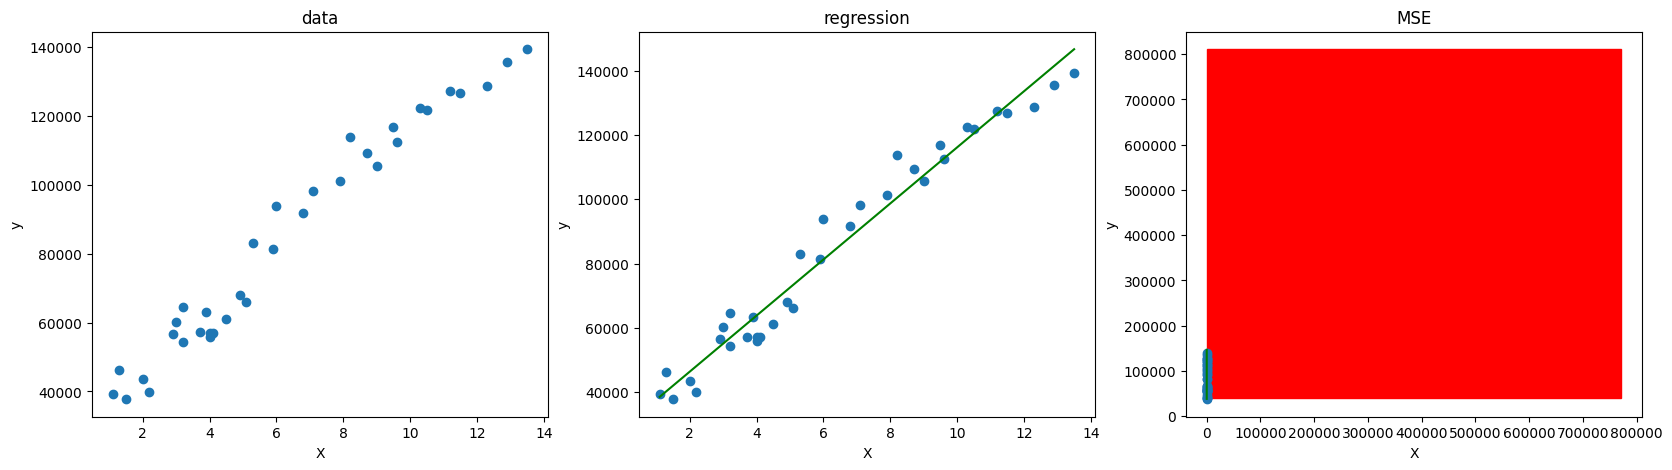

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].set_title('data')
axes[0].set_xlabel('X')
axes[0].set_ylabel('y')

axes[1].set_title('regression')
axes[1].set_xlabel('X')
axes[1].set_ylabel('y')

axes[2].set_title('MSE')
axes[2].set_xlabel('X')
axes[2].set_ylabel('y')

axes[0].plot([x[0] for x in df.data], [y[1] for y in df.data], 'o')

axes[1].plot([x[0] for x in df.data], [y[1] for y in df.data], 'o')
axes[1].plot([l[0] for l in line], [l[1] for l in line], color='g')

axes[2].plot([x[0] for x in df.data], [y[1] for y in df.data], 'o')
axes[2].plot([l[0] for l in line], [l[1] for l in line], color='g')

for i ,m in enumerate(mse):
    axes[2].add_patch(plt.Rectangle(df.data[i], m, m, color='r'))